In [1]:
# NAME - SHAURYANSH SINGH
#COURSE- BTECH-CSEAIML
#ADM:NO- 2026B15310221


In [2]:
from google.colab import files

In [3]:
upload = files.upload()
filename=next(iter(upload))

Saving online_retail_II.xlsx to online_retail_II.xlsx


In [15]:
#we need to see the files
import os
print(os.listdir())

['.config', 'online_retail_II (1).xlsx', 'online_retail_II.xlsx', 'sample_data']


In [16]:
import numpy as np
import pandas as pd

In [17]:
x= pd.read_excel("online_retail_II.xlsx")
print(x.head())

  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

          InvoiceDate  Price  Customer ID         Country  
0 2009-12-01 07:45:00   6.95      13085.0  United Kingdom  
1 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
2 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
3 2009-12-01 07:45:00   2.10      13085.0  United Kingdom  
4 2009-12-01 07:45:00   1.25      13085.0  United Kingdom  


In [18]:
(x.head())

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [20]:
(x.shape)

(525461, 8)

In [21]:
(x.columns)

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='object')

In [22]:
print(x.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[ns]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 32.1+ MB
None


In [23]:
("Column Names:")
(x.columns)

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='object')

In [24]:
("Data Types:")
(x.dtypes)

,0
Invoice,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
Price,float64
Customer ID,float64
Country,object


In [25]:
expected_schema = {
    "Invoice":	"object",
"StockCode": "object",
"Description":	"object",
"Quantity":	"int64",
"InvoiceDate":	"datetime64[ns]",
"Price":	"float64",
"Customer ID":	"float64",
"Country":	"object",
}
("Expected Schema:")
(expected_schema)

{'Invoice': 'object',
 'StockCode': 'object',
 'Description': 'object',
 'Quantity': 'int64',
 'InvoiceDate': 'datetime64[ns]',
 'Price': 'float64',
 'Customer ID': 'float64',
 'Country': 'object'}

In [26]:
key_columns=["Invoice","StockCode","InvoiceDate"]
("Candidate Keys:",key_columns)
("First Date:",x["InvoiceDate"].min())
("Last Date:",x["InvoiceDate"].max())

#in key_column we have use only three to gettransaction record

('Last Date:', Timestamp('2010-12-09 20:01:00'))

In [27]:
missing_values=x.isnull().sum()
(missing_values)

,0
Invoice,0
StockCode,0
Description,2928
Quantity,0
InvoiceDate,0
Price,0
Customer ID,107927
Country,0


In [28]:
duplicates= x.duplicated().sum()
("Total Duplicates Rows:",duplicates)

('Total Duplicates Rows:', np.int64(6865))

In [29]:
("Invalid Quantity:",(x["Quantity"]<=0).sum())
("Invalid Price:",(x["Price"]<0).sum())

('Invalid Price:', np.int64(3))

In [30]:
x.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,525461.000000,525461,525461.000000,417534.000000
mean,10.337667,2010-06-28 11:37:36.845017856,4.688834,15360.645478
min,-9600.000000,2009-12-01 07:45:00,-53594.360000,12346.000000
25%,1.000000,2010-03-21 12:20:00,1.250000,13983.000000
50%,3.000000,2010-07-06 09:51:00,2.100000,15311.000000
75%,10.000000,2010-10-15 12:45:00,4.210000,16799.000000
max,19152.000000,2010-12-09 20:01:00,25111.090000,18287.000000
std,107.424110,NaN,146.126914,1680.811316


In [49]:
print("Reference Columns:")
print(reference_data.columns.tolist())
print("\nCurrent Columns:")
print(current_data.columns.tolist())

Reference Columns:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Current Columns:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


In [50]:
x['InvoiceDate'] = pd.to_datetime(x['InvoiceDate'])

x = x.sort_values('InvoiceDate')

split_date = x['InvoiceDate'].median()

reference_data = x[x['InvoiceDate'] <= split_date]

current_data = x[x['InvoiceDate'] > split_date]

In [51]:
(reference_data.shape)
(current_data.shape)

(262592, 8)

In [34]:
("Reference Data Types:")
(reference_data.dtypes)
("Current Data Types:")
(current_data.dtypes)

,0
Invoice,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
Price,float64
Customer ID,float64
Country,object


In [35]:
("Reference Mean:")
(reference_data.select_dtypes(include='number').mean())
("Current Mean:")
(current_data.select_dtypes(include='number').mean())

,0
Quantity,10.032255
Price,4.555797
Customer ID,15380.125048


In [36]:
import numpy as np

In [37]:
reference_mean = reference_data['Quantity'].mean()
current_mean = current_data['Quantity'].mean()
change = abs(current_mean - reference_mean) / abs(reference_mean) * 100
("Percentage Change:", change)

('Percentage Change:', np.float64(5.736314689171214))

In [38]:
reference_price = reference_data['Price'].mean()
current_price = current_data['Price'].mean()
price_change = abs(current_price - reference_price) / abs(reference_price) * 100
("Price Change:", price_change)

('Price Change:', np.float64(5.515346892905018))

In [39]:
warning_threshold = 10
critical_threshold = 25
if change >= critical_threshold:
    ("Critical Drift")
elif change >= warning_threshold:
    ("Warning Drift")
else:
  ("Normal")

In [40]:
late_data = reference_data.tail(5)
simulated_current = pd.concat([current_data,late_data])
("Original rows:", (current_data))
("After late data:",(simulated_current))

('After late data:',
        Invoice StockCode                         Description  Quantity  \
 262880  514729    15044B                 BLUE PAPER PARASOL         50   
 262889  514729     71459      HANGING JAM JAR T-LIGHT HOLDER       432   
 262888  514729     20961             STRAWBERRY BATH SPONGE         80   
 262887  514729     20963                   APPLE BATH SPONGE        80   
 262886  514729     20960              WATERMELON BATH SPONGE        80   
 ...        ...       ...                                 ...       ...   
 262717  514728     21917     SET 12 KIDS  WHITE CHALK STICKS         1   
 262716  514728     21892  TRADITIONAL WOODEN CATCH CUP GAME          1   
 262715  514728     21891    TRADITIONAL WOODEN SKIPPING ROPE         1   
 262714  514728     21866         UNION JACK FLAG LUGGAGE TAG         1   
 262719  514728     21934                  SKULL SHOULDER BAG         2   
 
                InvoiceDate  Price  Customer ID         Country  
 262880 201

In [41]:
duplicate_data=pd.concat([simulated_current,simulated_current.head(5)])
("Total Duplicates:",duplicate_data.duplicated().sum())

('Total Duplicates:', np.int64(3769))

In [42]:
category_data = duplicate_data.copy()
category_data.loc[category_data.index[0], 'Country'] = 'Unknown'
(category_data['Country'].value_counts().head())

,count
Country,
United Kingdom,241694
EIRE,5063
Germany,3884
France,3105
Netherlands,1484


In [43]:
("DATA QUALITY MONITORING REPORT")
("Total Rows:", len(category_data))
("Missing Values:", category_data.isnull().sum().sum())
("Duplicate Rows:", category_data.duplicated().sum())
("Unknown Countries:", (category_data['Country'] == 'Unknown').sum())
("Invalid Quantity:", (category_data['Quantity'] <= 0).sum())
("Invalid Price:", (category_data['Price'] < 0).sum())

('Invalid Price:', np.int64(2))

In [44]:
if category_data.isnull().sum().sum() > 0:
    ("ALERT: Missing values found")
if category_data.duplicated().sum() > 0:
    ("ALERT: Duplicate records found")
if (category_data['Country'] == 'Unknown').sum() > 0:
    ("ALERT: Category changes found")
("Monitoring completed")

'Monitoring completed'

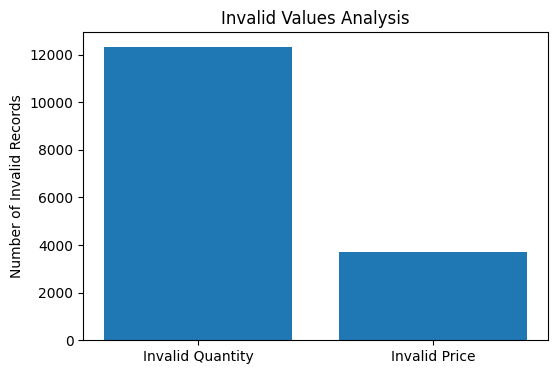

In [53]:
import matplotlib.pyplot as plt

invalid_quantity = (x['Quantity'] <= 0).sum()
invalid_price = (x['Price'] <= 0).sum()

plt.figure(figsize=(6,4))

plt.bar(
    ['Invalid Quantity', 'Invalid Price'],
    [invalid_quantity, invalid_price]
)

plt.title("Invalid Values Analysis")
plt.ylabel("Number of Invalid Records")

plt.show()

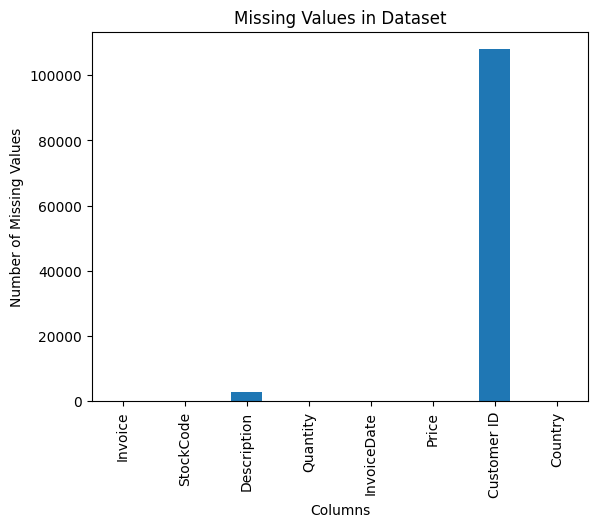

In [46]:
x.isnull().sum().plot(kind='bar')

plt.title("Missing Values in Dataset")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")

plt.show()

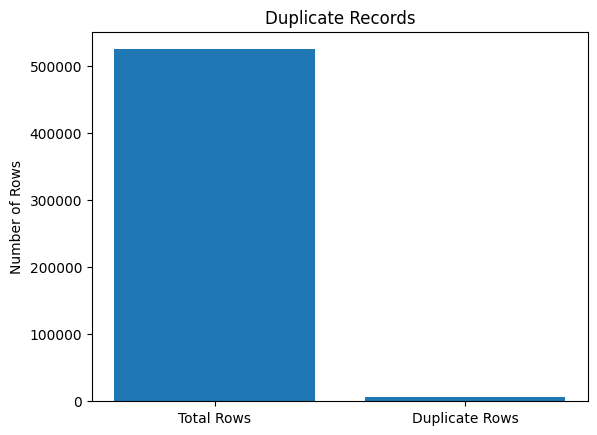

In [47]:
plt.bar(
    ['Total Rows', 'Duplicate Rows'],
    [len(x), x.duplicated().sum()]
)

plt.title("Duplicate Records")
plt.ylabel("Number of Rows")

plt.show()

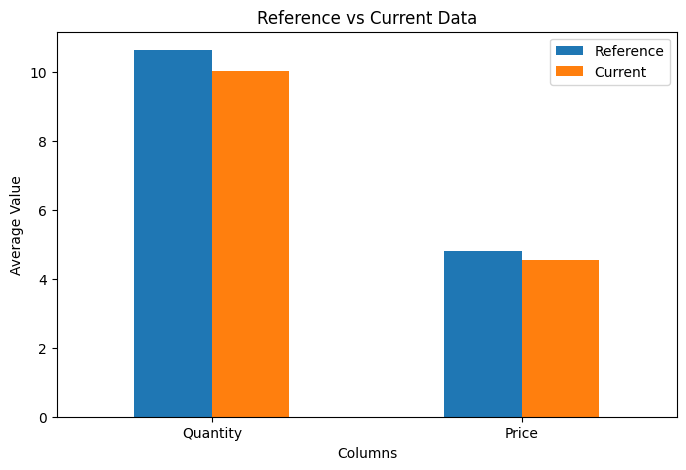

In [54]:
comparison = pd.DataFrame({
    'Reference': reference_data[['Quantity', 'Price']].mean(),
    'Current': current_data[['Quantity', 'Price']].mean()
})

comparison.plot(kind='bar', figsize=(8,5))

plt.title("Reference vs Current Data")
plt.xlabel("Columns")
plt.ylabel("Average Value")
plt.xticks(rotation=0)

plt.show()